# Aprendizaje automático: Iris y diabetes

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Se entrenan dos árboles de clasificación independientes. Cada conjunto conserva sus propias particiones, predicciones y métricas.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)

Python: 3.12.14
NumPy: 2.5.5


## 1. Análisis exploratorio y preparación

En diabetes, los ceros de glucosa, presión, espesor de piel, insulina e IMC se tratan como ausentes. El cero de embarazos se conserva. La imputación por mediana se ajusta dentro de cada entrenamiento, sin usar prueba.

In [2]:
from ia_unidad3 import trees
for name in ('Iris', 'Diabetes'):
    frame, y, classes = trees.load_data(name)
    print('\nDATASET:', name, 'filas:', len(frame), 'clases:', classes)
    print(frame.head().to_string(index=False))
    print('Faltantes:', frame.isna().sum().to_dict())
    print('Duplicados de variables:', frame.duplicated().sum())


DATASET: Iris filas: 150 clases: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
 Largo sépalo  Ancho sépalo  Largo pétalo  Ancho pétalo
          5.1           3.5           1.4           0.2
          4.9           3.0           1.4           0.2
          4.7           3.2           1.3           0.2
          4.6           3.1           1.5           0.2
          5.0           3.6           1.4           0.2
Faltantes: {'Largo sépalo': 0, 'Ancho sépalo': 0, 'Largo pétalo': 0, 'Ancho pétalo': 0}
Duplicados de variables: 3

DATASET: Diabetes filas: 768 clases: ['Sin diabetes', 'Con diabetes']
 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age
           6    148.0           72.0           35.0      NaN 33.6                     0.627   50
           1     85.0           66.0           29.0      NaN 26.6                     0.351   31
           8    183.0           64.0            NaN      NaN 23.3                     0.672   32
   

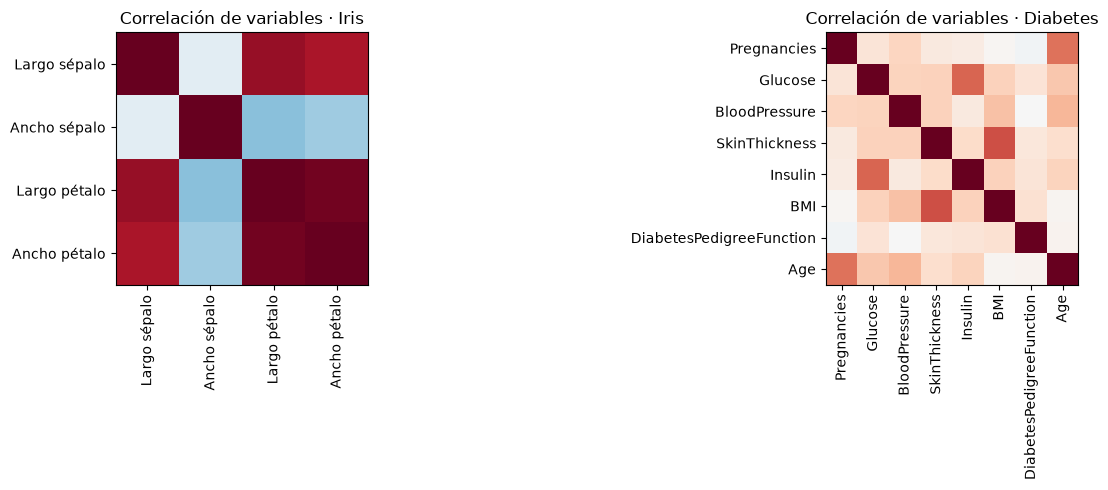

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ('Iris', 'Diabetes')):
    frame, _, _ = trees.load_data(name)
    matrix = frame.corr()
    ax.imshow(matrix, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set(title=f'Correlación de variables · {name}', xticks=range(len(frame.columns)), yticks=range(len(frame.columns)), xticklabels=frame.columns, yticklabels=frame.columns)
    ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout(); plt.show()

## 2. Entrenamiento y elección de profundidad

Se reserva el 20% como prueba. Del 80% restante, un cuarto se usa para validación: 60/20/20 del total. Se comparan profundidades 2–6 mediante F1 macro y se favorece el árbol más pequeño en caso de empate.

In [4]:
experiments = {}
for name in ('Iris', 'Diabetes'):
    record, model, frame = trees.experiment(name)
    experiments[name] = (record, model)
    print('\n', name, 'selección:', record['seleccion'])
    print('Profundidad:', record['profundidad'], 'Exactitud:', round(record['accuracy'],4), 'F1 macro:', round(record['f1_macro'],4))
    for label, values in record['reporte'].items(): print(label, values)
    trees.export_experiment(Path('resultados/cuaderno')/name.lower(), record, model)


 Iris selección: [{'profundidad': 2, 'f1_macro': 0.9333333333333332}, {'profundidad': 3, 'f1_macro': 0.9333333333333332}, {'profundidad': 4, 'f1_macro': 0.9333333333333332}, {'profundidad': 5, 'f1_macro': 0.9333333333333332}, {'profundidad': 6, 'f1_macro': 0.9333333333333332}]
Profundidad: 2 Exactitud: 0.9333 F1 macro: 0.9333
Iris-setosa {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 10.0}
Iris-versicolor {'precision': 0.9, 'recall': 0.9, 'f1-score': 0.9, 'support': 10.0}
Iris-virginica {'precision': 0.9, 'recall': 0.9, 'f1-score': 0.9, 'support': 10.0}
accuracy 0.9333333333333333
macro avg {'precision': 0.9333333333333332, 'recall': 0.9333333333333332, 'f1-score': 0.9333333333333332, 'support': 30.0}
weighted avg {'precision': 0.9333333333333333, 'recall': 0.9333333333333333, 'f1-score': 0.9333333333333333, 'support': 30.0}

 Diabetes selección: [{'profundidad': 2, 'f1_macro': 0.7127277945185824}, {'profundidad': 3, 'f1_macro': 0.7127277945185824}, {'profundidad': 4, '

## 3. Árbol de Iris y evaluación

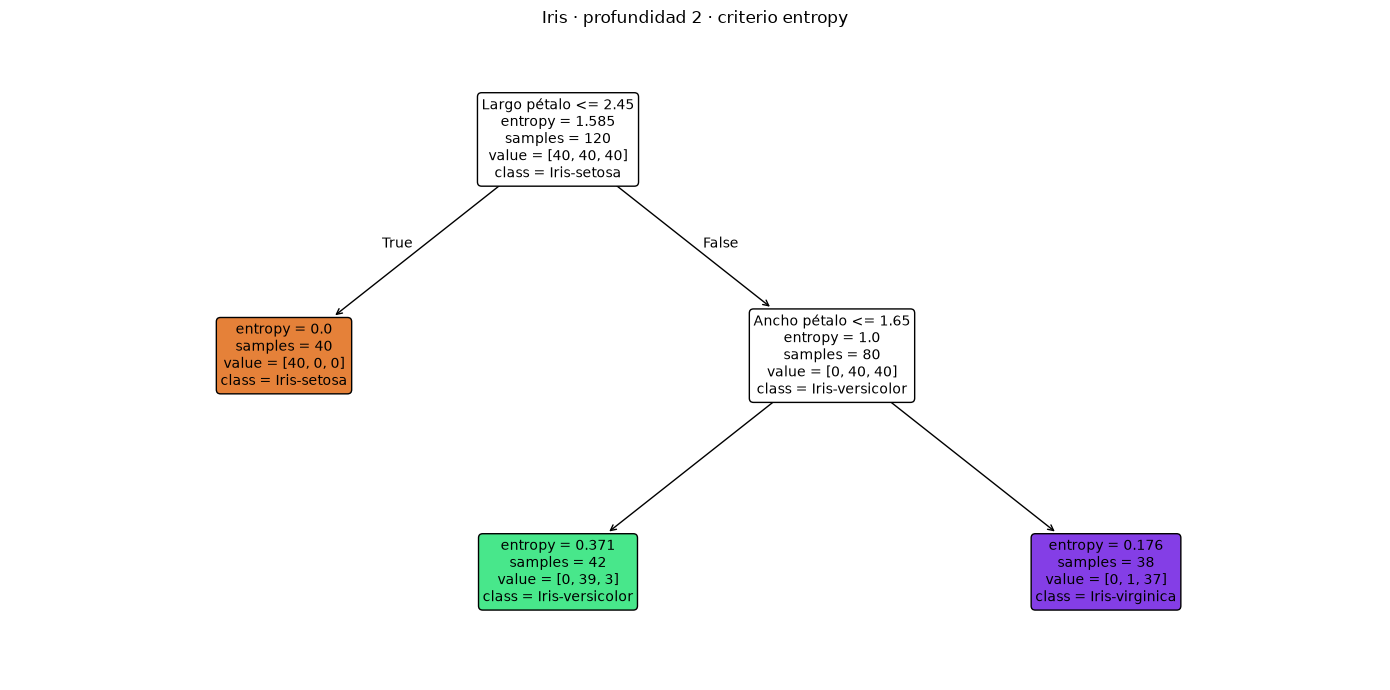

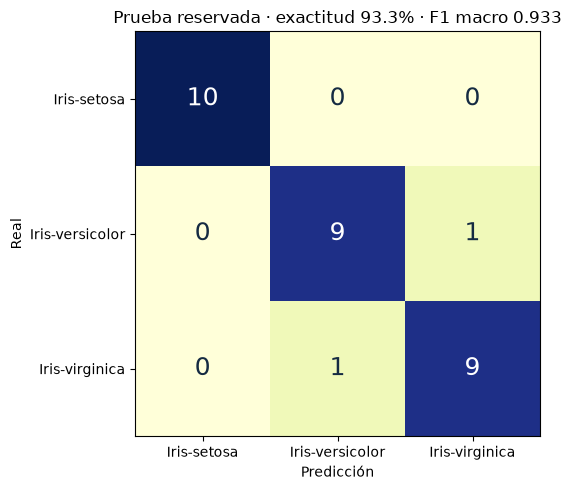

In [5]:
record, model = experiments['Iris']
fig=plt.figure(figsize=(14,7)); trees.draw(fig,record,model,'Árbol'); plt.show()
fig=plt.figure(figsize=(7,5)); trees.draw(fig,record,model,'Confusión'); plt.show()

## 4. Árbol de diabetes y evaluación

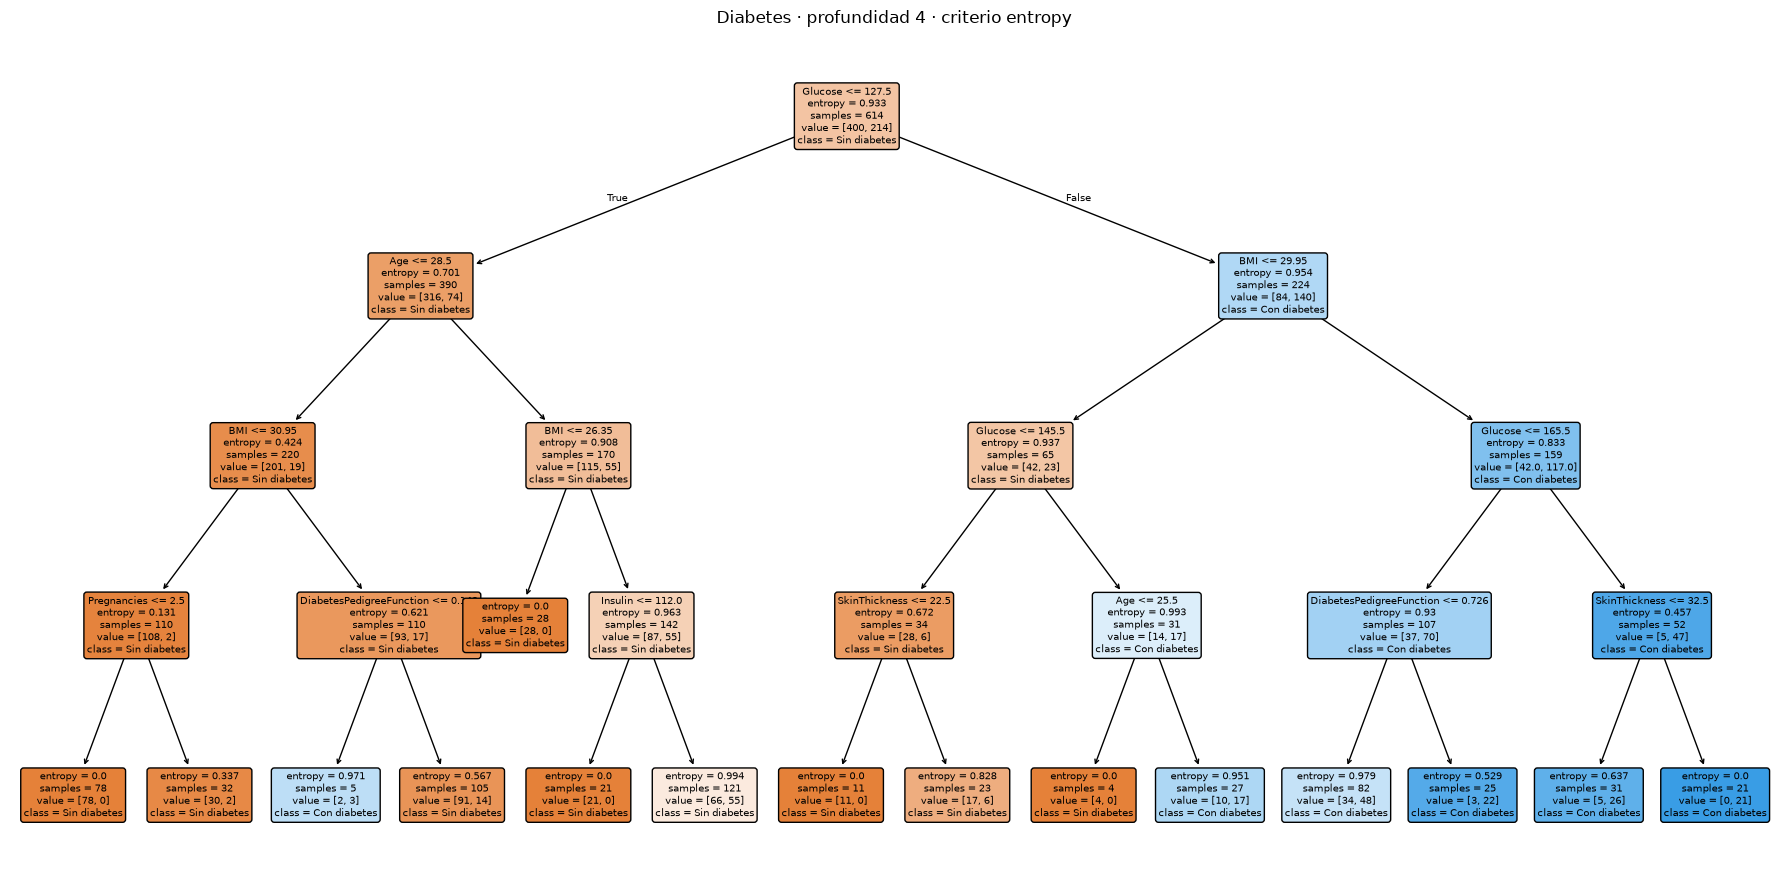

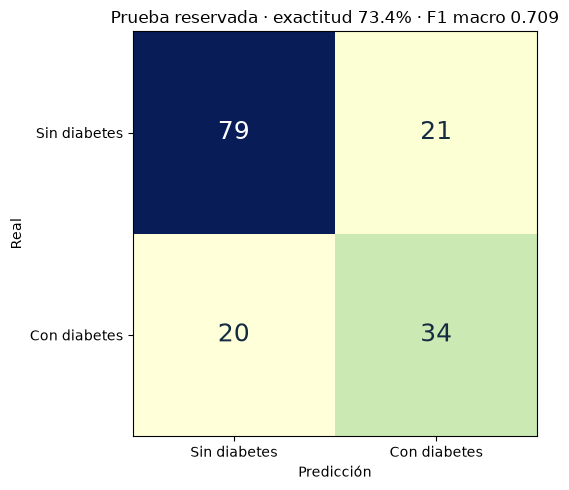

In [6]:
record, model = experiments['Diabetes']
fig=plt.figure(figsize=(18,9)); trees.draw(fig,record,model,'Árbol'); plt.show()
fig=plt.figure(figsize=(7,5)); trees.draw(fig,record,model,'Confusión'); plt.show()

## Conclusiones

La profundidad seleccionada depende del conjunto de datos. Se informa exactitud, F1 macro y matriz de confusión de cada problema de clasificación; no se reutilizan las predicciones de diabetes al evaluar Iris. Las métricas son de una partición reproducible y no garantizan generalización a otras poblaciones. Los valores faltantes se imputan a partir de los datos de entrenamiento.